In [1]:
!pip install catboost lightgbm shap xgboost

Defaulting to user installation because normal site-packages is not writeable


In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC, SVC
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score, confusion_matrix, f1_score
import time
import numpy as np
import shap
import pandas as pd
import os
from xgboost import XGBClassifier
import joblib

In [ ]:
# Define directories for loading features
load_dir = "saved_features_final"

In [3]:
# load the metadata
X_train_scaled = np.load(os.path.join(load_dir, "X_train_scaled.npy"))
X_val_scaled   = np.load(os.path.join(load_dir, "X_val_scaled.npy"))
X_test_scaled  = np.load(os.path.join(load_dir, "X_test_scaled.npy"))

y_train_meta = np.load(os.path.join(load_dir, "y_train_meta.npy"))
y_val_meta   = np.load(os.path.join(load_dir, "y_val_meta.npy"))
y_test_meta  = np.load(os.path.join(load_dir, "y_test_meta.npy"))

In [ ]:
# load the feature names for the metadata features
metadata_feature_names = joblib.load(os.path.join(load_dir, "metadata_feature_names.pkl"))

In [5]:
# Convert to DataFrames
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=metadata_feature_names)
X_val_scaled_df   = pd.DataFrame(X_val_scaled, columns=metadata_feature_names)
X_test_scaled_df  = pd.DataFrame(X_test_scaled, columns=metadata_feature_names)

y_train_series = pd.Series(y_train_meta)
y_val_series   = pd.Series(y_val_meta)
y_test_series  = pd.Series(y_test_meta)

In [ ]:
# logistic regression model with hyperparameter tuning using GridSearchCV
def train_logistic_regression(X_train, X_test, y_train, y_test, feature_names=None):
    lr = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)

    param_grid = {
        'C': [0.01, 0.1, 1, 10],
        'penalty': ['l2'], 
        'solver': ['lbfgs']
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(lr, param_grid, scoring='roc_auc', cv=cv, verbose=1, n_jobs=-1)

    print("Training Logistic Regression with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:,1]

    print("Best parameters:", grid_search.best_params_)
    print("Validation ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Validation Accuracy:", accuracy_score(y_test, y_pred))
    print("Validation F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    if feature_names is None:
        if hasattr(X_train, 'columns'):
            feature_names = X_train.columns
        else:
            feature_names = [f'feature_{i}' for i in range(X_train.shape[1])]

    feature_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': best_model.coef_[0]
    }).sort_values('importance', key=abs, ascending=False)
    print("\nTop 10 Feature Importances:\n", feature_importance.head(10))

    return best_model, feature_importance

In [ ]:
# Train logistic regression on the metadata features (first validation)
feature_names_for_lr = metadata_feature_names

# check that the number of features in X_train_scaled matches the number of feature names
assert X_train_scaled.shape[1] == len(feature_names_for_lr), "Feature names count does not match number of features in X_train_scaled"
print(f"Training Logistic Regression with {len(feature_names_for_lr)} features...")

start_time = time.time()
lr_model, lr_feature_importance = train_logistic_regression(
    X_train_scaled_df, 
    X_val_scaled_df,
    y_train_meta, 
    y_val_meta,
)
end_time = time.time()
print(f"Logistic Regression training completed in {end_time - start_time:.2f} seconds.")

Training Logistic Regression with 91 features...

Training Logistic Regression with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


c:\Code\VirtEnv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}

Validation ROC-AUC: 0.838025520798314
Validation Accuracy: 0.762117452440033
Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.75      0.76      2962
           1       0.76      0.77      0.77      3083

    accuracy                           0.76      6045
   macro avg       0.76      0.76      0.76      6045
weighted avg       0.76      0.76      0.76      6045


Top 10 Feature Importances:
                             feature  importance
6        category_parent_name_Dance    1.090747
62           goal_converted_USD_log   -1.040294
81                 num_reward_tiers    0.997349
5       category_parent_name_Crafts   -0.909510
13       category_parent_name_Music    0.765001
83              prelaunch_activated    0.718852
17     category_parent_name_Theater    0.706489
90                            video    0.657629
12  category_parent_name_Journalism   -0.560

In [ ]:
# Train logistic regression on the metadata features (test set)
feature_names_for_lr = metadata_feature_names

assert X_train_scaled.shape[1] == len(feature_names_for_lr), "Feature names count does not match number of features in X_train_scaled"
print(f"Training Logistic Regression with {len(feature_names_for_lr)} features...")

start_time = time.time()
lr_model, lr_feature_importance = train_logistic_regression(
    X_train_scaled_df,
    X_test_scaled_df, 
    y_train_meta,
    y_test_meta,
)
end_time = time.time()
print(f"Logistic Regression training completed in {end_time - start_time:.2f} seconds.")

Training Logistic Regression with 91 features...

Training Logistic Regression with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits


c:\Code\VirtEnv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



Best parameters: {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}

Validation ROC-AUC: 0.8534299790427998
Validation Accuracy: 0.7719153159113463
Validation F1 Score: 0.7758088115753536
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.77      0.77      2962
           1       0.78      0.77      0.78      3084

    accuracy                           0.77      6046
   macro avg       0.77      0.77      0.77      6046
weighted avg       0.77      0.77      0.77      6046


Top 10 Feature Importances:
                             feature  importance
6        category_parent_name_Dance    1.090747
62           goal_converted_USD_log   -1.040294
81                 num_reward_tiers    0.997349
5       category_parent_name_Crafts   -0.909510
13       category_parent_name_Music    0.765001
83              prelaunch_activated    0.718852
17     category_parent_name_Theater    0.706489
90                            video    0.657629
12

In [ ]:
# Predicted probabilities
y_train_pred = lr_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = lr_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = lr_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC scores
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)
print(f"Train AUC: {train_auc:.4f}")
print(f"Validation AUC: {val_auc:.4f}")
print(f"Test AUC: {test_auc:.4f}")
print(f"AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

Train AUC: 0.8472
Validation AUC: 0.8380
Test AUC: 0.8534
AUC gap for validation (overfitting indicator): 0.0092
AUC gap for test (overfitting indicator): -0.0062


In [ ]:
# multiply each LR coefficient by the standard deviation of its feature to get standardized coefficients, it rescales each coefficient to the same “unit variance” scale
# get coefficients and feature names
coefficients = lr_model.coef_[0]

feature_stds = X_train_scaled_df.std()
standardized_coefficients = coefficients * feature_stds

standardized_feature_importance = pd.DataFrame({
    'feature': feature_stds.index,
    'standardized_importance': standardized_coefficients.values
}).sort_values('standardized_importance', key=abs, ascending=False)

print("Top 10 Standardized Feature Importances:", standardized_feature_importance.head(10))


Top 10 Standardized Feature Importances:
                        feature  standardized_importance
62      goal_converted_USD_log                -1.040313
81            num_reward_tiers                 0.997366
90                       video                 0.313963
83         prelaunch_activated                 0.301133
85         rewards_char_length                -0.293953
82           num_static_images                 0.286604
88          total_media_assets                 0.281090
2       campaign_duration_days                -0.273052
13  category_parent_name_Music                 0.252504
87           story_char_length                 0.206294


/work/.venv/lib/python3.12/site-packages/shap/explainers/_linear.py:123: FutureWarning: The feature_perturbation option is now deprecated in favor of using the appropriate masker (maskers.Independent, maskers.Partition or maskers.Impute).
  warnings.warn(wmsg, FutureWarning)


Top 10 features by mean absolute SHAP value:
goal_converted_USD_log        0.817680
num_reward_tiers              0.667746
video                         0.282295
prelaunch_activated           0.238826
category_parent_name_Music    0.206219
campaign_duration_days        0.204695
num_static_images             0.201921
total_media_assets            0.195231
rewards_char_length           0.182793
story_char_length             0.148045
dtype: float64


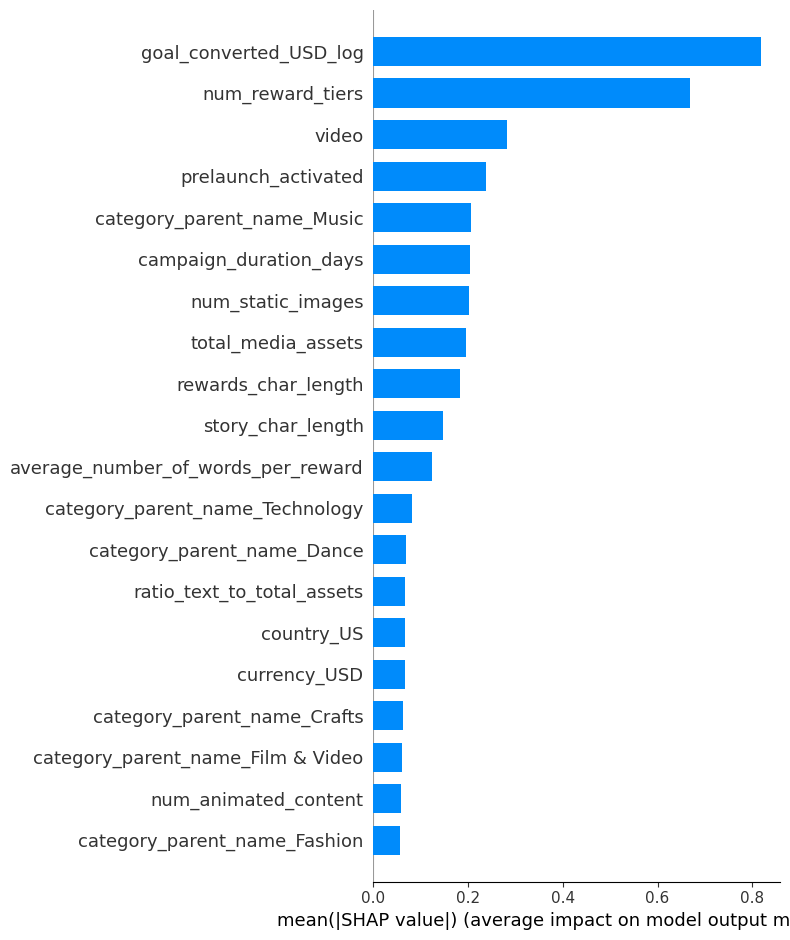

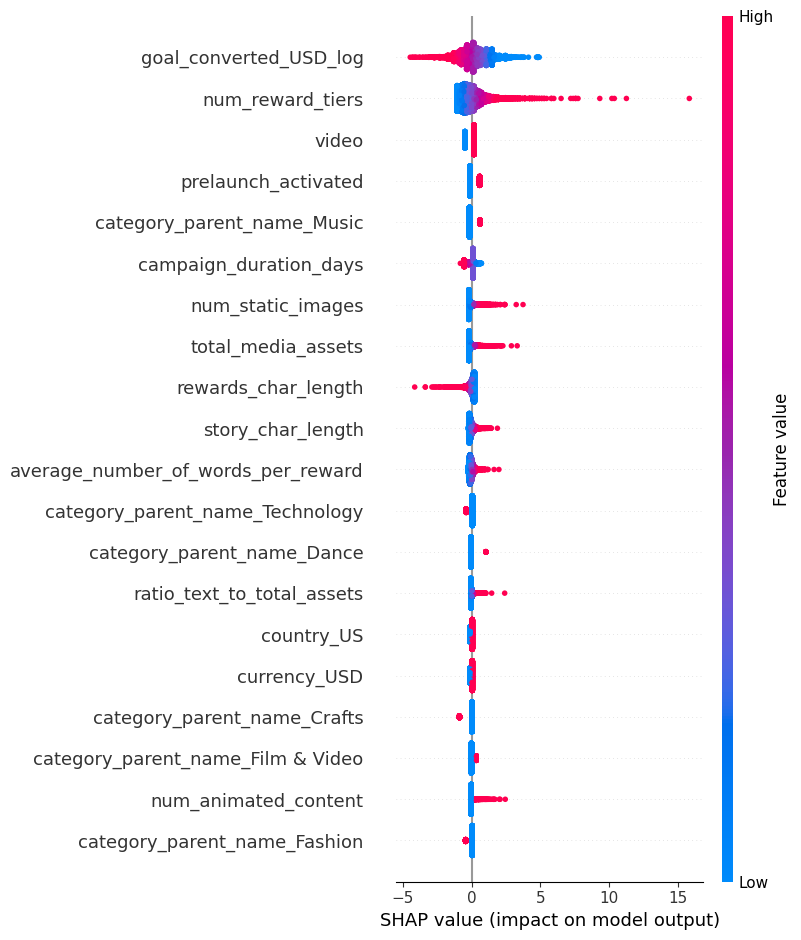

In [ ]:
# SHAP values for logistic regression
explainer = shap.LinearExplainer(lr_model, X_train_scaled_df, feature_perturbation="interventional")
shap_values = explainer.shap_values(X_test_scaled_df)

# convert to dataframe for better visualization
shap_df = pd.DataFrame(shap_values, columns=feature_names_for_lr)

# Mean absolute SHAP values per feature (common "feature importance" metric)
shap_importance = pd.DataFrame(shap_values, columns=X_test_scaled_df.columns).abs().mean().sort_values(ascending=False)

# Show top 10 features
print("Top 10 features by mean absolute SHAP value:")
print(shap_importance.head(10))

# SHAP summary plot
shap.summary_plot(shap_values, X_test_scaled_df, plot_type="bar")

# SHAP dot summary plot
shap.summary_plot(shap_values, X_test_scaled_df, plot_type="dot")

In [ ]:
# Train decision tree on the metadata features
def train_decision_tree(X_train, X_test, y_train, y_test):
    start_time = time.time()

    dt = DecisionTreeClassifier(random_state=42)

    param_grid = {
        'max_depth': [None, 5, 10, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(dt, param_grid, scoring='roc_auc', cv=cv, verbose=1, n_jobs=-1)

    print("\nTraining Decision Tree with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:,1]

    print("Best parameters:", grid_search.best_params_)
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    # Feature names from the DataFrame columns
    cols = X_train.columns if hasattr(X_train, 'columns') else [f'f_{i}' for i in range(X_train.shape[1])]

    feature_importance = pd.DataFrame({
        'feature': cols,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print("\nTop 10 Feature Importances:\n", feature_importance.head(10))

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"\nDecision Tree training and evaluation took: {elapsed_time:.2f} seconds")

    return best_model, feature_importance

In [16]:
# apply 
dt_model, dt_features = train_decision_tree(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training Decision Tree with GridSearchCV...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}

Test ROC-AUC: 0.7947522877630657
Test Accuracy: 0.7315136476426799
Test F1 Score: 0.7451719265190768
Classification Report:
               precision    recall  f1-score   support

           0       0.74      0.69      0.72      2962
           1       0.72      0.77      0.75      3083

    accuracy                           0.73      6045
   macro avg       0.73      0.73      0.73      6045
weighted avg       0.73      0.73      0.73      6045


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log    0.282713
81               num_reward_tiers    0.232249
89              total_text_length    0.062998
82              num_static_images    0.057149
88             total_media_assets    0.054073
83            prelaunch_activated    0.030217
61  

In [17]:
# apply 
dt_model, dt_features = train_decision_tree(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training Decision Tree with GridSearchCV...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

Best parameters: {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 10}

Test ROC-AUC: 0.8069805627003873
Test Accuracy: 0.7433013562686074
Test F1 Score: 0.7568922305764411
Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.70      0.73      2962
           1       0.73      0.78      0.76      3084

    accuracy                           0.74      6046
   macro avg       0.74      0.74      0.74      6046
weighted avg       0.74      0.74      0.74      6046


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log    0.282713
81               num_reward_tiers    0.232249
89              total_text_length    0.062998
82              num_static_images    0.057149
88             total_media_assets    0.054073
83            prelaunch_activated    0.030217
61  

In [ ]:
# Predicted probabilities
y_train_pred = dt_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = dt_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = dt_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)

print(f"Decision Tree Train AUC: {train_auc:.4f}")
print(f"Decision Tree Validation AUC: {val_auc:.4f}")
print(f"Decision Tree Test AUC: {test_auc:.4f}")
print(f"Decision Tree AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"Decision Tree AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

Decision Tree Train AUC: 0.8901
Decision Tree Validation AUC: 0.7948
Decision Tree Test AUC: 0.8070
Decision Tree AUC gap for validation (overfitting indicator): 0.0953
Decision Tree AUC gap for test (overfitting indicator): 0.0831


Random Forest

In [ ]:
# random forest with hyperparameter tuning using GridSearchCV
def train_random_forest_lighter(X_train, X_test, y_train, y_test):
    start_time = time.time()

    rf = RandomForestClassifier(random_state=42, n_jobs=-1, class_weight='balanced')

    param_grid_lighter = {
        'n_estimators': [100, 200],
        'max_depth': [5, 10, 20],
        'min_samples_split': [5],
        'min_samples_leaf': [2],
        'max_features': ['sqrt']
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(
        estimator=rf,
        param_grid=param_grid_lighter,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1,
        return_train_score=True
    )

    print("Training Lighter Random Forest with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)

    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:,1]

    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    cols = X_train.columns if hasattr(X_train, 'columns') else [f'f_{i}' for i in range(X_train.shape[1])]

    # Feature importance from the best random forest model
    feature_importance = pd.DataFrame({
        'feature': cols,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print("Top 10 Feature Importances:\n", feature_importance.head(10))

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f" Random Forest training and evaluation took: {elapsed_time:.2f} seconds")

    return best_model, feature_importance

In [17]:
rf_model_lighter, rf_feature_importance_lighter = train_random_forest_lighter(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training Lighter Random Forest with GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Test ROC-AUC: 0.8591824697875983
Test Accuracy: 0.7791563275434243
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.73      0.77      2962
           1       0.76      0.82      0.79      3083

    accuracy                           0.78      6045
   macro avg       0.78      0.78      0.78      6045
weighted avg       0.78      0.78      0.78      6045


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log    0.133958
81               num_reward_tiers    0.071466
85            rewards_char_length    0.061182
89              total_text_length    0.056001
88             total_media_assets    0.049236
2          campaign_duration_days 

In [19]:
rf_model_lighter, rf_feature_importance_lighter = train_random_forest_lighter(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training Lighter Random Forest with GridSearchCV...
Fitting 5 folds for each of 6 candidates, totalling 30 fits

Best parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Test ROC-AUC: 0.8589779883715125
Test Accuracy: 0.7782004631161098
Test F1 Score: 0.7879841897233202
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.75      0.77      2962
           1       0.77      0.81      0.79      3084

    accuracy                           0.78      6046
   macro avg       0.78      0.78      0.78      6046
weighted avg       0.78      0.78      0.78      6046


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log    0.133958
81               num_reward_tiers    0.071466
85            rewards_char_length    0.061182
89              total_text_length    0.056001
88             total_media_assets    0.049236


In [19]:
# Predicted probabilities
y_train_pred = rf_model_lighter.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = rf_model_lighter.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = rf_model_lighter.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)
print(f"Random Forest Train AUC: {train_auc:.4f}")
print(f"Random Forest Validation AUC: {val_auc:.4f}")
print(f"Random Forest Test AUC: {test_auc:.4f}")
print(f"Random Forest AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"Random Forest AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

Random Forest Train AUC: 0.9951
Random Forest Validation AUC: 0.8592
Random Forest Test AUC: 0.8590
Random Forest AUC gap for validation (overfitting indicator): 0.1359
Random Forest AUC gap for test (overfitting indicator): 0.1361


XGBoost

In [ ]:
# XGBoost with hyperparameter tuning using GridSearchCV
def train_xgboost(X_train, X_test, y_train, y_test):
    start_time = time.time()

    xgb = XGBClassifier(
        eval_metric='auc',
        random_state=42
    )

    param_grid = {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 4, 5],
        'learning_rate': [0.05, 0.1],
        'min_child_weight': [1, 3],
        'subsample': [0.7, 0.9],
        'colsample_bytree': [0.7, 0.9],
        'gamma': [0, 0.1]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(xgb, param_grid, scoring='roc_auc', cv=cv, verbose=1, n_jobs=-1, return_train_score=True)
    print("Training XGBoost with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)

    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:,1]

    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    cols = X_train.columns if hasattr(X_train, 'columns') else [f'f_{i}' for i in range(X_train.shape[1])]

    feature_importance = pd.DataFrame({
        'feature': cols,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)
    print("Top 10 Feature Importances:\n", feature_importance.head(10))

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"XGBoost training and evaluation took: {elapsed_time:.2f} seconds")
    return best_model, feature_importance

In [7]:
# apply XGBoost training
xgb_model, xgb_feature_importance = train_xgboost(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training XGBoost with GridSearchCV...
Fitting 5 folds for each of 288 candidates, totalling 1440 fits


KeyboardInterrupt: 

In [11]:
# apply XGBoost training
xgb_model, xgb_feature_importance = train_xgboost(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training XGBoost with GridSearchCV...
Fitting 5 folds for each of 288 candidates, totalling 1440 fits

Best parameters: {'colsample_bytree': 0.9, 'gamma': 0.1, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.7}

Test ROC-AUC: 0.8758292456721586
Test Accuracy: 0.7924247436321535
Test F1 Score: 0.80270397736205
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.76      0.78      2962
           1       0.78      0.83      0.80      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046


Top 10 Feature Importances:
                        feature  importance
81            num_reward_tiers    0.078697
82           num_static_images    0.044586
62      goal_converted_USD_log    0.044564
13  category_parent_name_Music    0.041235
90                       video    0.041121

In [23]:
# Predicted probabilities
y_train_pred = xgb_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = xgb_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = xgb_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)
print(f"XGBoost Train AUC: {train_auc:.4f}")
print(f"XGBoost Validation AUC: {val_auc:.4f}")
print(f"XGBoost Test AUC: {test_auc:.4f}")
print(f"XGBoost AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"XGBoost AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

XGBoost Train AUC: 0.9150
XGBoost Validation AUC: 0.8695
XGBoost Test AUC: 0.8758
XGBoost AUC gap for validation (overfitting indicator): 0.0456
XGBoost AUC gap for test (overfitting indicator): 0.0392


In [ ]:
# Create the SHAP explainer for a tree-based model
explainer = shap.TreeExplainer(xgb_model)

# Compute SHAP values for the training set
shap_values = explainer.shap_values(X_train_scaled_df)

# Mean absolute SHAP values per feature
shap_importance = pd.DataFrame(shap_values, columns=X_train_scaled_df.columns).abs().mean().sort_values(ascending=False)

# Show top 10 features
print("Top 10 features by mean absolute SHAP value:")
print(shap_importance.head(10))

# SHAP summary plot (bar)
shap.summary_plot(shap_values, X_train_scaled, plot_type="bar")

# SHAP dot summary plot
shap.summary_plot(shap_values, X_train_scaled, plot_type="dot")

LGBM

In [ ]:
# Train LightGBM with hyperparameter tuning using GridSearchCV
def train_lgbm(X_train, X_test, y_train, y_test):
    start_time = time.time()

    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

    lgbm = LGBMClassifier(
        random_state=42,
        scale_pos_weight=scale_pos_weight,
        verbose=-1
    )

    param_grid = {
        'n_estimators': [100, 300],
        'max_depth': [-1, 6],
        'num_leaves': [31, 63],
        'learning_rate': [0.03, 0.1],
        'min_child_samples': [20, 40],
        'subsample': [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(
        lgbm,
        param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1
    )

    print("Training LightGBM with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("Best parameters:", grid_search.best_params_)
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    cols = X_train.columns if hasattr(X_train, 'columns') else [f'f_{i}' for i in range(X_train.shape[1])]

    # Feature importance from the best LightGBM model
    feature_importance = pd.DataFrame({
        'feature': cols,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)

    print("Top 10 Feature Importances:\n", feature_importance.head(10))

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"LightGBM training and evaluation took: {elapsed_time:.2f} seconds")
    return best_model, feature_importance

In [25]:
# apply
lgbm_model, lgbm_feature_importance = train_lgbm(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training LightGBM with GridSearchCV...
Fitting 5 folds for each of 128 candidates, totalling 640 fits

Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': -1, 'min_child_samples': 40, 'n_estimators': 300, 'num_leaves': 31, 'subsample': 0.8}

Test ROC-AUC: 0.8692645495773801
Test Accuracy: 0.7831265508684864
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.75      0.77      2962
           1       0.77      0.82      0.79      3083

    accuracy                           0.78      6045
   macro avg       0.78      0.78      0.78      6045
weighted avg       0.78      0.78      0.78      6045


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log        1166
79        lowest_pledge_level_usd         528
65       highest_pledge_level_usd         498
86              risks_char_length         476
81               num_reward_tiers         475
2     

In [21]:
# apply
lgbm_model, lgbm_feature_importance = train_lgbm(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training LightGBM with GridSearchCV...
Fitting 5 folds for each of 128 candidates, totalling 640 fits

Best parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': -1, 'min_child_samples': 40, 'n_estimators': 300, 'num_leaves': 31, 'subsample': 0.8}

Test ROC-AUC: 0.8742421296649038
Test Accuracy: 0.7940787297386702
Test F1 Score: 0.8024123155054753
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.77      0.79      2962
           1       0.79      0.82      0.80      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log        1166
79        lowest_pledge_level_usd         528
65       highest_pledge_level_usd         498
86              risks_char_length         476
81               n

In [27]:
# Predicted probabilities
y_train_pred = lgbm_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = lgbm_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = lgbm_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)
print(f"LightGBM Train AUC: {train_auc:.4f}")
print(f"LightGBM Validation AUC: {val_auc:.4f}")
print(f"LightGBM Test AUC: {test_auc:.4f}")
print(f"LightGBM AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"LightGBM AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

LightGBM Train AUC: 0.9111
LightGBM Validation AUC: 0.8693
LightGBM Test AUC: 0.8742
LightGBM AUC gap for validation (overfitting indicator): 0.0419
LightGBM AUC gap for test (overfitting indicator): 0.0369


In [ ]:
# Train CatBoost with hyperparameter tuning using GridSearchCV
def train_catboost(X_train, X_test, y_train, y_test):
    start_time = time.time()

    neg = int((y_train == 0).sum())
    pos = int((y_train == 1).sum())
    scale_pos_weight = float(neg / max(pos, 1)) 

    catboost = CatBoostClassifier(
        loss_function='Logloss',
        eval_metric='AUC',
        random_state=42,
        scale_pos_weight=scale_pos_weight,
        verbose=False
    )

    param_grid = {
        'iterations': [200, 300],
        'depth': [4, 6, 8],
        'learning_rate': [0.03, 0.05, 0.1]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(
        catboost,
        param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1
    )

    print("Training CatBoost with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("Best parameters:", grid_search.best_params_)
    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    cols = X_train.columns if hasattr(X_train, 'columns') else [f'f_{i}' for i in range(X_train.shape[1])]

    # Feature importance from the best CatBoost model
    feature_importance = pd.DataFrame({
        'feature': cols,
        'importance': best_model.feature_importances_
    }).sort_values('importance', ascending=False)

    print("Top 10 Feature Importances:\n", feature_importance.head(10))
    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"CatBoost training and evaluation took: {elapsed_time:.2f} seconds")

    return best_model, feature_importance

In [11]:
# apply
catboost_model, catboost_feature_importance = train_catboost(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training CatBoost with GridSearchCV...
Fitting 5 folds for each of 18 candidates, totalling 90 fits


c:\Code\VirtEnv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
9 fits failed out of a total of 90.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
9 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Code\VirtEnv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Code\VirtEnv\Lib\site-packages\catboost\core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
  File "c:\Code\VirtEnv\Lib\site-packages\catboost\core.py", line 2716, in _fit
    self._train(
  File 


Best parameters: {'depth': 6, 'iterations': 300, 'learning_rate': 0.1}

Test ROC-AUC: 0.8700607741304442
Test Accuracy: 0.7851116625310174
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.75      0.77      2962
           1       0.77      0.82      0.79      3083

    accuracy                           0.79      6045
   macro avg       0.79      0.78      0.78      6045
weighted avg       0.79      0.79      0.78      6045


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log   22.979879
81               num_reward_tiers   10.169401
2          campaign_duration_days    4.574665
88             total_media_assets    4.334156
79        lowest_pledge_level_usd    3.852940
65       highest_pledge_level_usd    3.803316
61  days_between_created_launched    3.664763
86              risks_char_length    3.235904
89              total_text_length    3.158632
85            rewar

In [23]:
# apply
catboost_model, catboost_feature_importance = train_catboost(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training CatBoost with GridSearchCV...
Fitting 5 folds for each of 18 candidates, totalling 90 fits

Best parameters: {'depth': 6, 'iterations': 300, 'learning_rate': 0.1}

Test ROC-AUC: 0.8774315782006584
Test Accuracy: 0.7945749255706253
Test F1 Score: 0.802355187778485
Classification Report:
               precision    recall  f1-score   support

           0       0.80      0.77      0.79      2962
           1       0.79      0.82      0.80      3084

    accuracy                           0.79      6046
   macro avg       0.79      0.79      0.79      6046
weighted avg       0.79      0.79      0.79      6046


Top 10 Feature Importances:
                           feature  importance
62         goal_converted_USD_log   22.979879
81               num_reward_tiers   10.169401
2          campaign_duration_days    4.574665
88             total_media_assets    4.334156
79        lowest_pledge_level_usd    3.852940
65       highest_pledge_level_usd    3.803316
61  days_between_create

In [ ]:
# Predicted probabilities
y_train_pred = catboost_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = catboost_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = catboost_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)
print(f"CatBoost Train AUC: {train_auc:.4f}")
print(f"CatBoost Validation AUC: {val_auc:.4f}")
print(f"CatBoost Test AUC: {test_auc:.4f}")
print(f"AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

Decision Tree Train AUC: 0.9192
Decision Tree Validation AUC: 0.8701
AUC gap (overfitting indicator): 0.0491


In [ ]:
# Train SVM with hyperparameter tuning using GridSearchCV and calibration
def train_svm(X_train, X_test, y_train, y_test, feature_names=None):
    start_time = time.time()

    svm_base = LinearSVC(
        class_weight='balanced',
        random_state=42,
        dual=False
    )

    param_grid = {
        'C': [0.01, 0.1, 1, 10]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(
        estimator=svm_base,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1,
        return_train_score=True
    )

    print("Training SVM with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_linear_svc = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)

    # Calibration phase (Platt scaling / sigmoid)
    svm_calibrated = CalibratedClassifierCV(
        best_linear_svc,
        method='sigmoid',
        cv=5
    )

    svm_calibrated.fit(X_train, y_train)

    # Predictions using calibrated model
    y_pred = svm_calibrated.predict(X_test)
    y_pred_proba = svm_calibrated.predict_proba(X_test)[:, 1]

    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    # Feature importance
    if feature_names is None:
        feature_names = (
            X_train.columns if hasattr(X_train, 'columns')
            else [f'f_{i}' for i in range(X_train.shape[1])]
        )

    coefs = svm_calibrated.calibrated_classifiers_[0].estimator.coef_[0]

    feature_importance = pd.DataFrame({
        'feature': feature_names,
        'importance': coefs
    }).sort_values('importance', key=abs, ascending=False)

    print("Top 10 Feature Importances:\n", feature_importance.head(10))

    end_time = time.time()
    print(f"SVM training and evaluation took: {end_time - start_time:.2f} seconds")

    return svm_calibrated, feature_importance

In [25]:
# get feature names for SVM
feature_names_for_svm = metadata_feature_names

In [ ]:
# apply
svm_model, svm_feature_importance = train_svm(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta, feature_names=feature_names_for_svm)


Training SVM with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best parameters: {'C': 0.01}

Test ROC-AUC: 0.8376322815781169
Test Accuracy: 0.76095947063689
Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.74      0.75      2962
           1       0.76      0.78      0.77      3083

    accuracy                           0.76      6045
   macro avg       0.76      0.76      0.76      6045
weighted avg       0.76      0.76      0.76      6045


Top 10 Feature Importances:
                             feature  importance
6        category_parent_name_Dance    0.417632
62           goal_converted_USD_log   -0.375402
5       category_parent_name_Crafts   -0.359438
81                 num_reward_tiers    0.357463
17     category_parent_name_Theater    0.300370
13       category_parent_name_Music    0.291714
83              prelaunch_activated    0.273817
90                            video    0.241

In [ ]:
# apply
svm_model, svm_feature_importance = train_svm(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta, feature_names=feature_names_for_svm)


Training SVM with GridSearchCV...
Fitting 5 folds for each of 4 candidates, totalling 20 fits

Best parameters: {'C': 0.01}

Test ROC-AUC: 0.8530983902453122
Test Accuracy: 0.773569302017863
Test F1 Score: 0.7799389165728983
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.76      0.77      2962
           1       0.77      0.79      0.78      3084

    accuracy                           0.77      6046
   macro avg       0.77      0.77      0.77      6046
weighted avg       0.77      0.77      0.77      6046


Top 10 Feature Importances:
                             feature  importance
6        category_parent_name_Dance    0.417632
62           goal_converted_USD_log   -0.375402
5       category_parent_name_Crafts   -0.359438
81                 num_reward_tiers    0.357463
17     category_parent_name_Theater    0.300370
13       category_parent_name_Music    0.291714
83              prelaunch_activated    0.273817
90       

In [21]:
# Predicted probabilities
y_train_pred = svm_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = svm_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = svm_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)

print(f"SVM Train AUC: {train_auc:.4f}")
print(f"SVM Validation AUC: {val_auc:.4f}")
print(f"SVM Test AUC: {test_auc:.4f}")
print(f"AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

SVM Train AUC: 0.8469
SVM Validation AUC: 0.8376
SVM Test AUC: 0.8531
AUC gap for validation (overfitting indicator): 0.0093
AUC gap for test (overfitting indicator): -0.0062


In [ ]:
# nonlinear SVM with RBF kernel and hyperparameter tuning using GridSearchCV
def train_svm_nonlinear(X_train, X_test, y_train, y_test, feature_names=None):
    start_time = time.time()

    # RBF Kernel SVM (nonlinear decision boundary)
    svm_base = SVC(
        kernel='rbf',
        class_weight='balanced',
        probability=True,
        random_state=42
    )

    # Parameter grid (small but effective)
    param_grid = {
        'C': [0.1, 1, 10],
        'gamma': ['scale', 0.01, 0.1]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    grid_search = GridSearchCV(
        estimator=svm_base,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1,
        return_train_score=True
    )

    print("Training Nonlinear SVM (RBF Kernel) with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)

    # Prediction
    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    end_time = time.time()
    print(f"Nonlinear SVM training and evaluation took: {end_time - start_time:.2f} seconds")

    return best_model

In [28]:
# train non-linear svm
svm_nonlinear_model = train_svm_nonlinear(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training Nonlinear SVM (RBF Kernel) with GridSearchCV...
Fitting 5 folds for each of 9 candidates, totalling 45 fits


KeyboardInterrupt: 

In [29]:
# train non-linear svm
svm_nonlinear_model = train_svm_nonlinear(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training Nonlinear SVM (RBF Kernel) with GridSearchCV...
Fitting 5 folds for each of 9 candidates, totalling 45 fits

Best parameters: {'C': 10, 'gamma': 0.01}

Test ROC-AUC: 0.8652668999720629
Test Accuracy: 0.7793582533906716
Test F1 Score: 0.7899874055415617
Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.74      0.77      2962
           1       0.77      0.81      0.79      3084

    accuracy                           0.78      6046
   macro avg       0.78      0.78      0.78      6046
weighted avg       0.78      0.78      0.78      6046


Nonlinear SVM training and evaluation took: 6622.68 seconds


In [25]:
# Predicted probabilities
y_train_pred = svm_nonlinear_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = svm_nonlinear_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = svm_nonlinear_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)

print(f"Non-linear SVM Train AUC: {train_auc:.4f}")
print(f"Non-linear SVM Validation AUC: {val_auc:.4f}")
print(f"Non-linear SVM Test AUC: {test_auc:.4f}")
print(f"AUC gap (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

Non-linear SVM Train AUC: 0.8861
Non-linear SVM Validation AUC: 0.8596
Non-linear SVM Test AUC: 0.8653
AUC gap (overfitting indicator): 0.0265
AUC gap for test (overfitting indicator): 0.0208


In [ ]:
# KNN with hyperparameter tuning using GridSearchCV
def train_knn(X_train, X_test, y_train, y_test):
    start_time = time.time()
    knn = KNeighborsClassifier(n_jobs=-1)

    param_grid = {
        'n_neighbors': [3, 5, 7, 9, 11],
        'weights': ['uniform', 'distance'],
        'metric': ['euclidean', 'manhattan']
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search = GridSearchCV(
        estimator=knn,
        param_grid=param_grid,
        scoring='roc_auc',
        cv=cv,
        verbose=1,
        n_jobs=-1,
        return_train_score=True
    )

    print("Training KNN with GridSearchCV...")
    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    print("Best parameters:", grid_search.best_params_)

    y_pred = best_model.predict(X_test)
    y_pred_proba = best_model.predict_proba(X_test)[:, 1]

    print("Test ROC-AUC:", roc_auc_score(y_test, y_pred_proba))
    print("Test Accuracy:", accuracy_score(y_test, y_pred))
    print("Test F1 Score:", f1_score(y_test, y_pred))
    print("Classification Report:\n", classification_report(y_test, y_pred))

    end_time = time.time()
    elapsed_time = end_time - start_time
    print(f"KNN training and evaluation took: {elapsed_time:.2f} seconds")

    return best_model

In [ ]:
# apply
knn_model = train_knn(X_train_scaled_df, X_val_scaled_df, y_train_meta, y_val_meta)


Training KNN with GridSearchCV...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}

Test ROC-AUC: 0.8234707418412444
Test Accuracy: 0.75136476426799
Classification Report:
               precision    recall  f1-score   support

           0       0.77      0.70      0.73      2962
           1       0.74      0.80      0.77      3083

    accuracy                           0.75      6045
   macro avg       0.75      0.75      0.75      6045
weighted avg       0.75      0.75      0.75      6045


KNN training and evaluation took: 801.19 seconds


In [ ]:
# apply
knn_model = train_knn(X_train_scaled_df, X_test_scaled_df, y_train_meta, y_test_meta)


Training KNN with GridSearchCV...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Best parameters: {'metric': 'manhattan', 'n_neighbors': 11, 'weights': 'distance'}

Test ROC-AUC: 0.8219451355737307
Test Accuracy: 0.7461131326496857
Test F1 Score: 0.758988852253101
Classification Report:
               precision    recall  f1-score   support

           0       0.76      0.71      0.73      2962
           1       0.74      0.78      0.76      3084

    accuracy                           0.75      6046
   macro avg       0.75      0.75      0.75      6046
weighted avg       0.75      0.75      0.75      6046


KNN training and evaluation took: 675.13 seconds


In [29]:
# Predicted probabilities
y_train_pred = knn_model.predict_proba(X_train_scaled_df)[:, 1]
y_val_pred   = knn_model.predict_proba(X_val_scaled_df)[:, 1]
y_test_pred  = knn_model.predict_proba(X_test_scaled_df)[:, 1]

# AUC
train_auc = roc_auc_score(y_train_meta, y_train_pred)
val_auc   = roc_auc_score(y_val_meta, y_val_pred)
test_auc  = roc_auc_score(y_test_meta, y_test_pred)

print(f"KNN Train AUC: {train_auc:.4f}")
print(f"KNN Validation AUC: {val_auc:.4f}")
print(f"KNN Test AUC: {test_auc:.4f}")
print(f"AUC gap for validation (overfitting indicator): {train_auc - val_auc:.4f}")
print(f"AUC gap for test (overfitting indicator): {train_auc - test_auc:.4f}")

KNN Train AUC: 1.0000
KNN Validation AUC: 0.8235
KNN Test AUC: 0.8219
AUC gap for validation (overfitting indicator): 0.1765
AUC gap for test (overfitting indicator): 0.1781
